In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
bank_directory = os.path.join(project_folder, 'analyses', 'basis meta neuron bank', 'saved', 'opticflow')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
from numpy import linalg as la
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

In [3]:
N = 93
K = 10

V_width = 1
V_E_buffer_array = np.arange(20).astype(int)
E_width = 1

In [4]:
sweep_dims = (len(V_E_buffer_array),)
bank_data = np.zeros(sweep_dims, dtype=object)
basis_neurons = np.zeros(sweep_dims, dtype=object)

for i, V_E_buffer in enumerate(V_E_buffer_array):
    load_path = os.path.join(bank_directory, f'({V_width},{V_E_buffer},{E_width}) K={K}.dat')
    with open(load_path, 'rb') as f:
        data_dict = pickle.load(f)
    basis_neurons[i] = data_dict["basis_vectors"]
    bank_data[i] = data_dict

mov_name = data_dict["mov_name"]

In [5]:
ref = basis_neurons[0]
for i in range(len(V_E_buffer_array)):
    for k in range(K):
        cur_leading = basis_neurons[i][:,k]
        cur_sign = np.sign(ref[:,k] @ cur_leading)
        basis_neurons[i][:,k] *= cur_sign

## "Capture": subspace overlap

The theory here is that two subspaces can be compared (is one spanned by the other?) by first constructing one projection operator for each basis, $P_1$ and $P_2$, then computing $\text{Tr} (P_1 P_2)$. For any single vector $v$, the quantity $v \cdot P_1 \cdot v$ would be the norm of the vector components spanned by $P_1$. Now, given that $P_2$ can be thought of as an outer product sum $v^\alpha_i v^\alpha_j$ of basis vectors, we get the trace formula:

\begin{equation*}
    (P_1)_{ij} v_i^\alpha v_j^\alpha = (P_1)_{ij} (P_2)_{ij}
\end{equation*}

Then finally, in the case that $\text{Span}(P_1) \in \text{Span}(P_2)$, we would have $\text{Tr}(P_1 P_2) = \text{min}(K_1, K_2)$ where $K_i$ are the ranks.

In [6]:
K_proj = 1

# Make a projection operator for each trial
P = np.zeros((len(V_E_buffer_array), V_width * N, V_width * N))
for i, V_E_buffer in enumerate(V_E_buffer_array):
    B = basis_neurons[i][:,:K_proj]
    # P[i] = B @ la.pinv(B.T @ B) @ B.T
    P[i] = B @ B.T  # the projection operators can actually just be written this way because B are orthogonal by construction.

In [76]:
capture = np.eye(len(V_E_buffer_array))
# capture = np.zeros((len(K_array), len(K_array)))
for i in range(len(V_E_buffer_array)):
    for j in range(i):
        capture[i, j] = np.trace(P[i] @ P[j]) / K_proj
        capture[j, i] = capture[i, j]

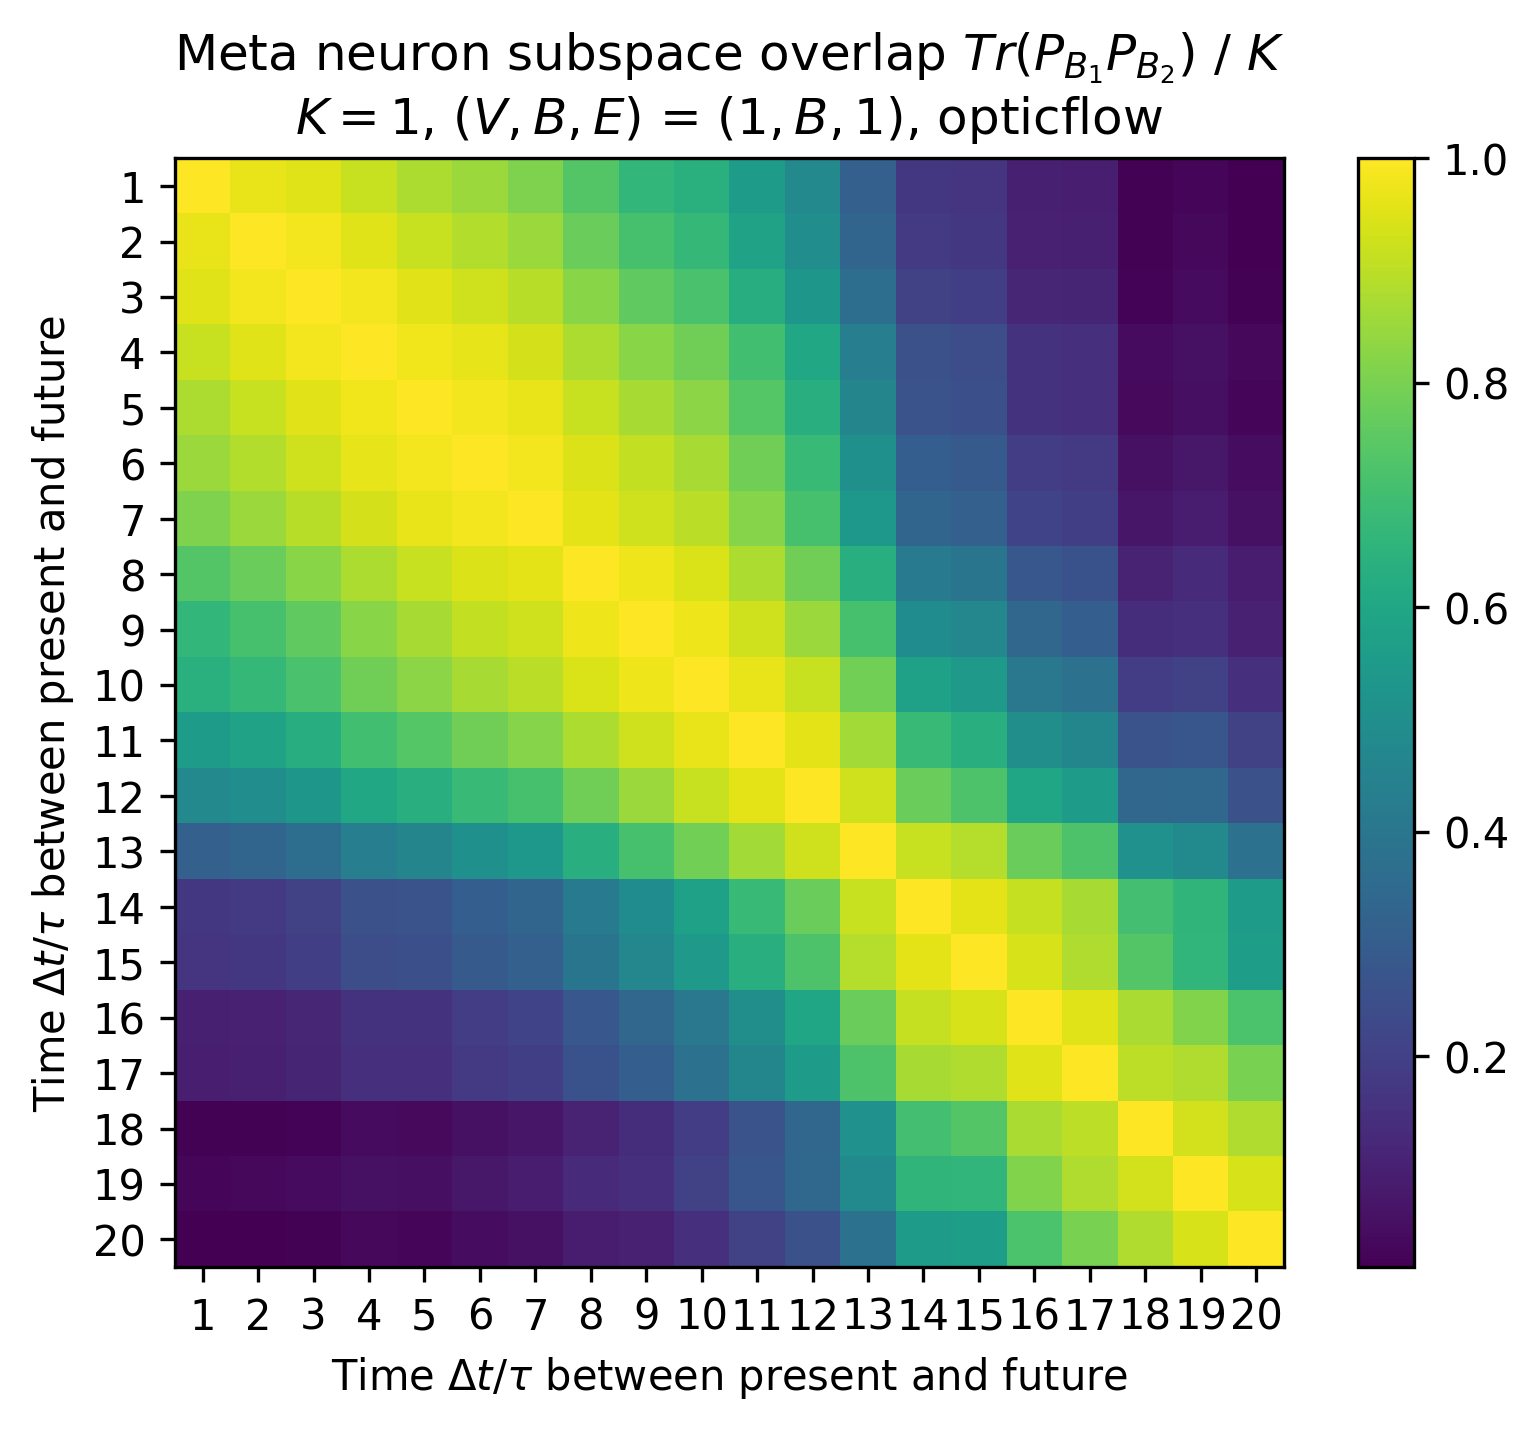

In [77]:
binsize = 1000 / 60
fig, ax = plt.subplots(dpi=300)
im = ax.imshow(capture)
plt.colorbar(im)
ax.set_title("Meta neuron subspace overlap $Tr(P_{B_1} P_{B_2})\  /\  K$ \n" +f"$K=${K_proj}, $(V,B,E)$ = $({V_width},B,{E_width})$, {mov_name}")
ax.set_xlabel(r"Time $\Delta t / \tau$ between present and future");
ax.set_ylabel(r"Time $\Delta t / \tau$ between present and future");
ax.set_aspect('equal')
ax.set_xticks(np.arange(len(V_E_buffer_array)));
ax.set_xticklabels(V_E_buffer_array + 1);
ax.set_yticks(np.arange(len(V_E_buffer_array)));
ax.set_yticklabels(V_E_buffer_array + 1);
# ax.set_xticklabels(K_array)
# ax.set_yticklabels(K_array)

## Meta neuron overlap by index

In [203]:
mode_index = 2

# Get the mdoe from each trial
B = np.zeros((len(V_E_buffer_array), V_width * N))
for i, V_E_buffer in enumerate(V_E_buffer_array):
    B[i] = basis_neurons[i][:,mode_index]

In [204]:
overlap = np.eye(len(V_E_buffer_array))
for i in range(len(V_E_buffer_array)):
    for j in range(i):
        overlap[i, j] = (B[i] @ B[j])**2
        overlap[j, i] = overlap[i, j]

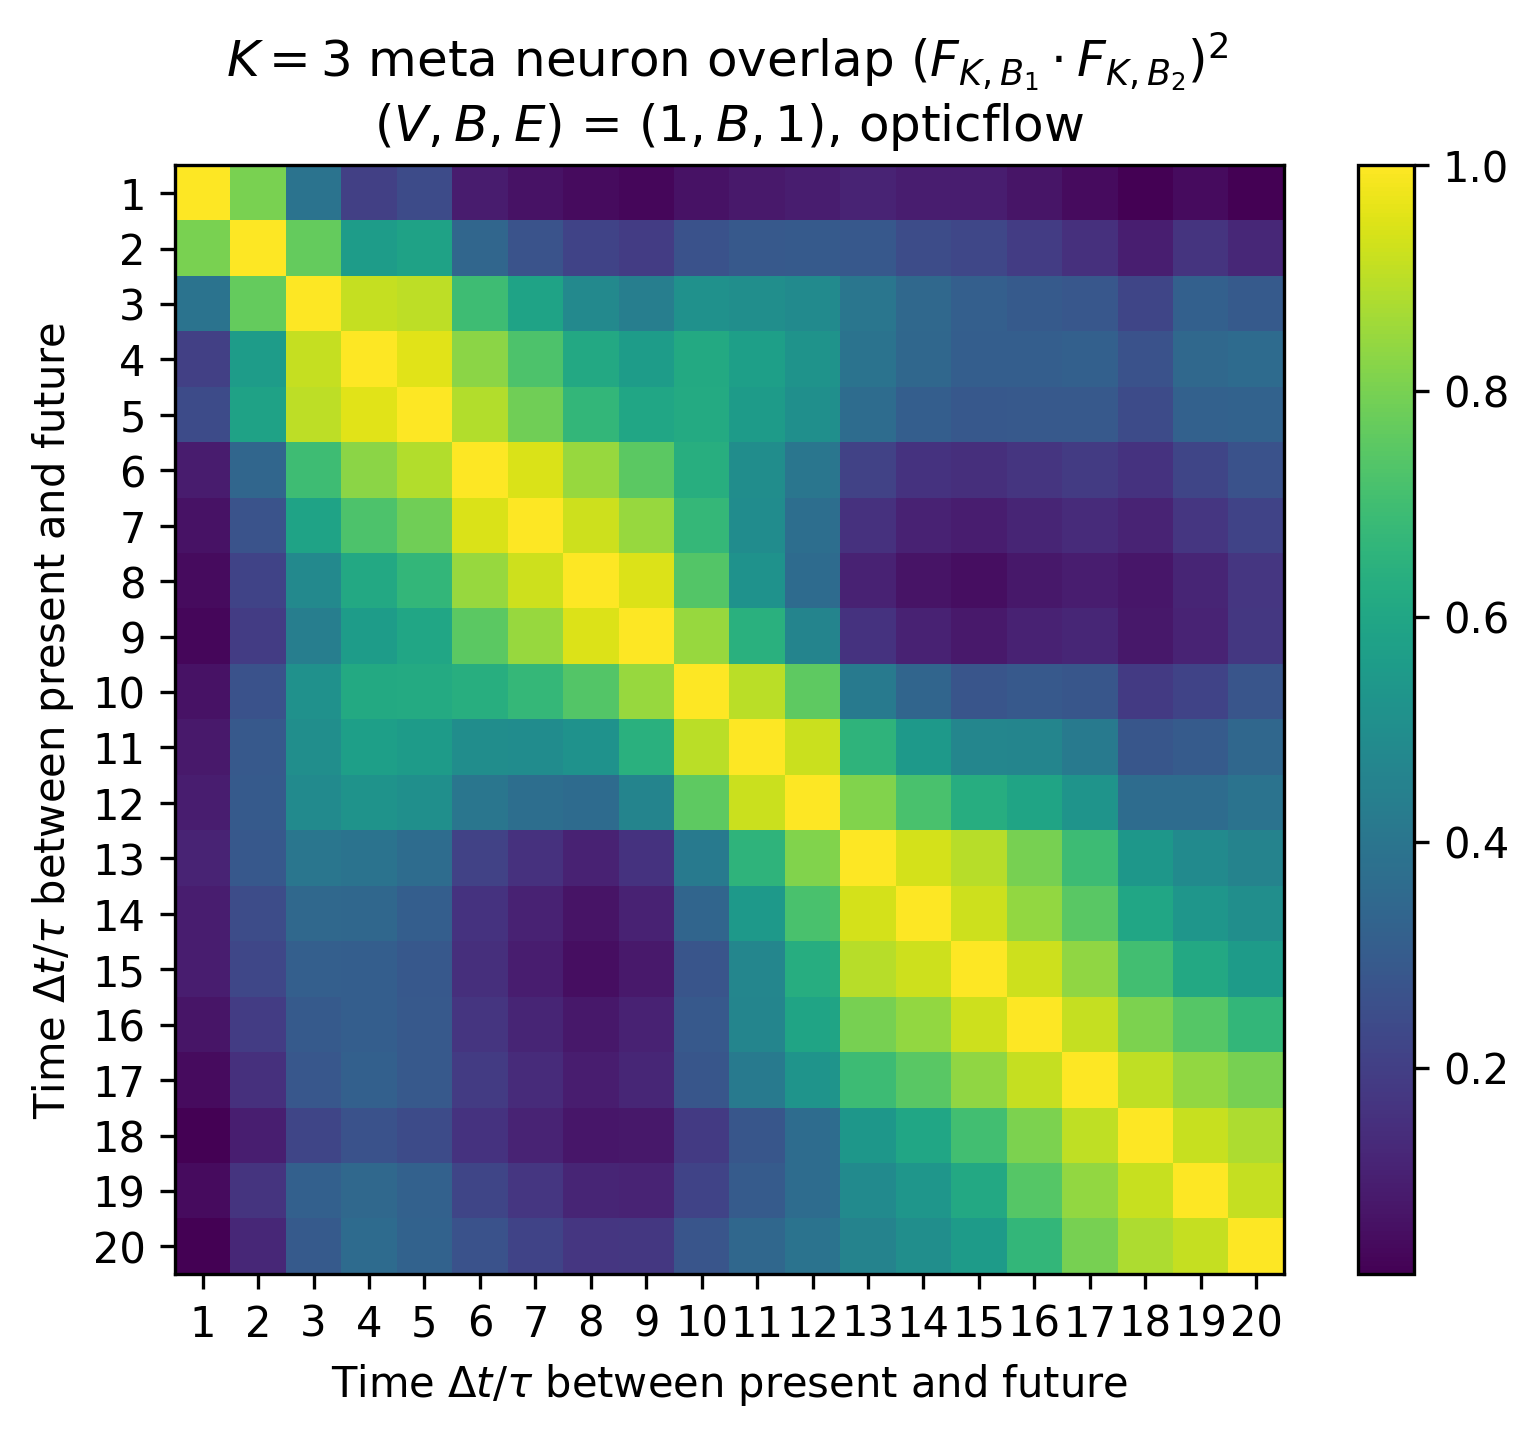

In [205]:
binsize = 1000 / 60
fig, ax = plt.subplots(dpi=300)
im = ax.imshow(overlap)
plt.colorbar(im)
ax.set_title(f"$K=${mode_index+1} meta neuron overlap" + " $(F_{K,B_1} \cdot F_{K,B_2})^2$ \n" +f"$(V,B,E)$ = $({V_width},B,{E_width})$, {mov_name}")
ax.set_xlabel(r"Time $\Delta t / \tau$ between present and future");
ax.set_ylabel(r"Time $\Delta t / \tau$ between present and future");
ax.set_aspect('equal')
ax.set_xticks(np.arange(len(V_E_buffer_array)));
ax.set_xticklabels(V_E_buffer_array + 1);
ax.set_yticks(np.arange(len(V_E_buffer_array)));
ax.set_yticklabels(V_E_buffer_array + 1);
# ax.set_xticklabels(K_array)
# ax.set_yticklabels(K_array)

## Cross-mode overlap

In [292]:
mode_1 = 1
mode_2 = 3

# Get the mdoe from each trial
B = np.zeros((len(V_E_buffer_array), V_width * N))
C = np.zeros((len(V_E_buffer_array), V_width * N))
for i, V_E_buffer in enumerate(V_E_buffer_array):
    B[i] = basis_neurons[i][:,mode_1]
    C[i] = basis_neurons[i][:,mode_2]

In [293]:
overlap = np.eye(len(V_E_buffer_array)) * 0
for i in range(len(V_E_buffer_array)):
    for j in range(i):
        overlap[i, j] = (B[i] @ C[j])**2
        overlap[j, i] = overlap[i, j]

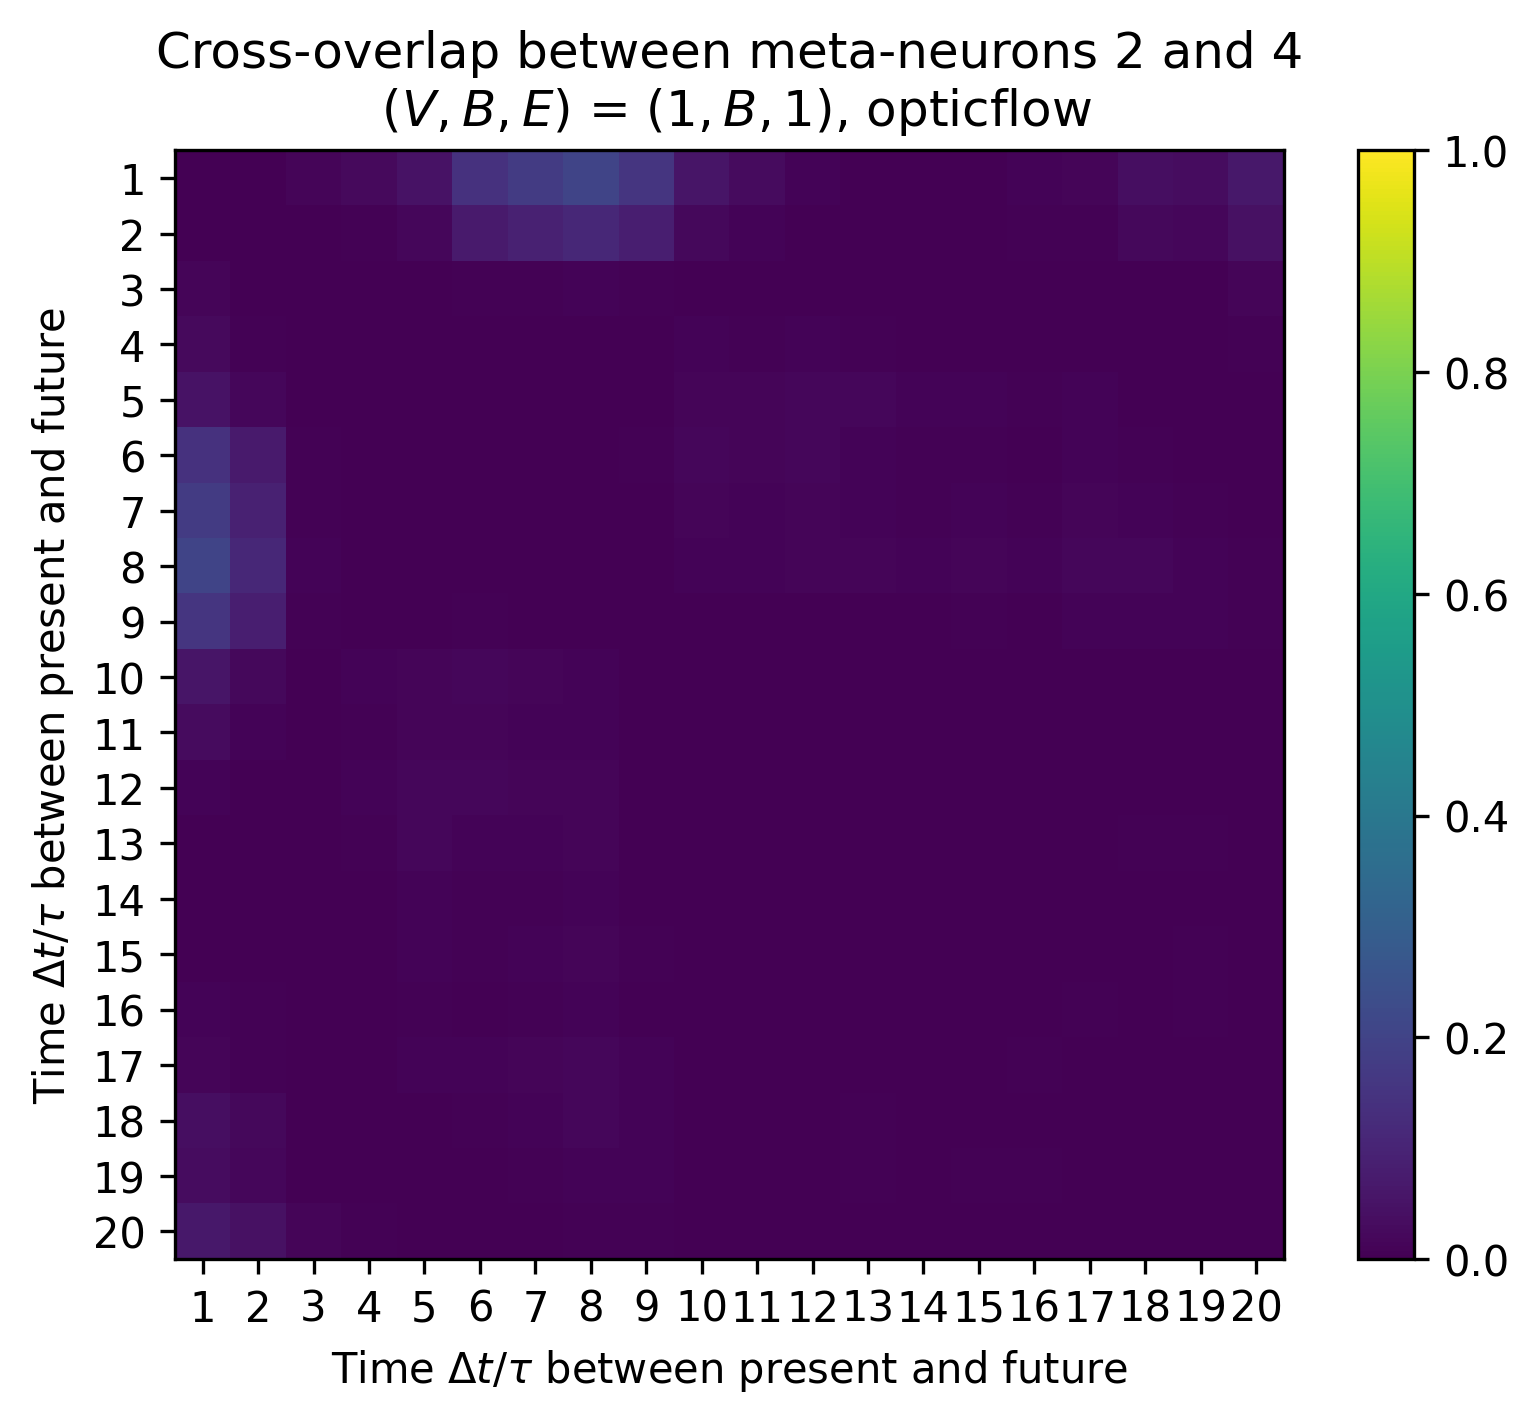

In [294]:
binsize = 1000 / 60
fig, ax = plt.subplots(dpi=300)
im = ax.imshow(overlap, vmax=1, vmin=0)
plt.colorbar(im)
ax.set_title(f"Cross-overlap between meta-neurons {mode_1+1} and {mode_2+1}\n $(V,B,E)$ = $({V_width},B,{E_width})$, {mov_name}")
ax.set_xlabel(r"Time $\Delta t / \tau$ between present and future");
ax.set_ylabel(r"Time $\Delta t / \tau$ between present and future");
ax.set_aspect('equal')
ax.set_xticks(np.arange(len(V_E_buffer_array)));
ax.set_xticklabels(V_E_buffer_array + 1);
ax.set_yticks(np.arange(len(V_E_buffer_array)));
ax.set_yticklabels(V_E_buffer_array + 1);
# ax.set_xticklabels(K_array)
# ax.set_yticklabels(K_array)

## Off diagonal sums

In [245]:
N_modes = 10

In [246]:
def diag_avg(M):
    N, _ = np.shape(M)
    return np.array([np.mean(np.diag(M,i)) for i in range(N)])

def get_overlap(mode_index):
    # Get the mdoe from each trial
    B = np.zeros((len(V_E_buffer_array), V_width * N))
    for i, V_E_buffer in enumerate(V_E_buffer_array):
        B[i] = basis_neurons[i][:,mode_index]
    
    overlap = np.eye(len(V_E_buffer_array))
    for i in range(len(V_E_buffer_array)):
        for j in range(i):
            overlap[i, j] = (B[i] @ B[j])**2
            overlap[j, i] = overlap[i, j]
    
    return overlap

In [247]:
off_diags_averaged = np.zeros((N_modes, len(V_E_buffer_array)))
for cur_mode in range(N_modes):
    cur_overlap = get_overlap(cur_mode)
    off_diags_averaged[cur_mode] = diag_avg(cur_overlap)

In [248]:
def unitize_range(x):
    return (x - np.min(x)) / (np.max(x) - np.min(x))

def linear_color(x, color_1, color_2):
    x = unitize_range(x)
    color_1 = np.array(color_1)
    color_2 = np.array(color_2)
    return [tuple((1 - y) * color_1 + y * color_2) for y in x]

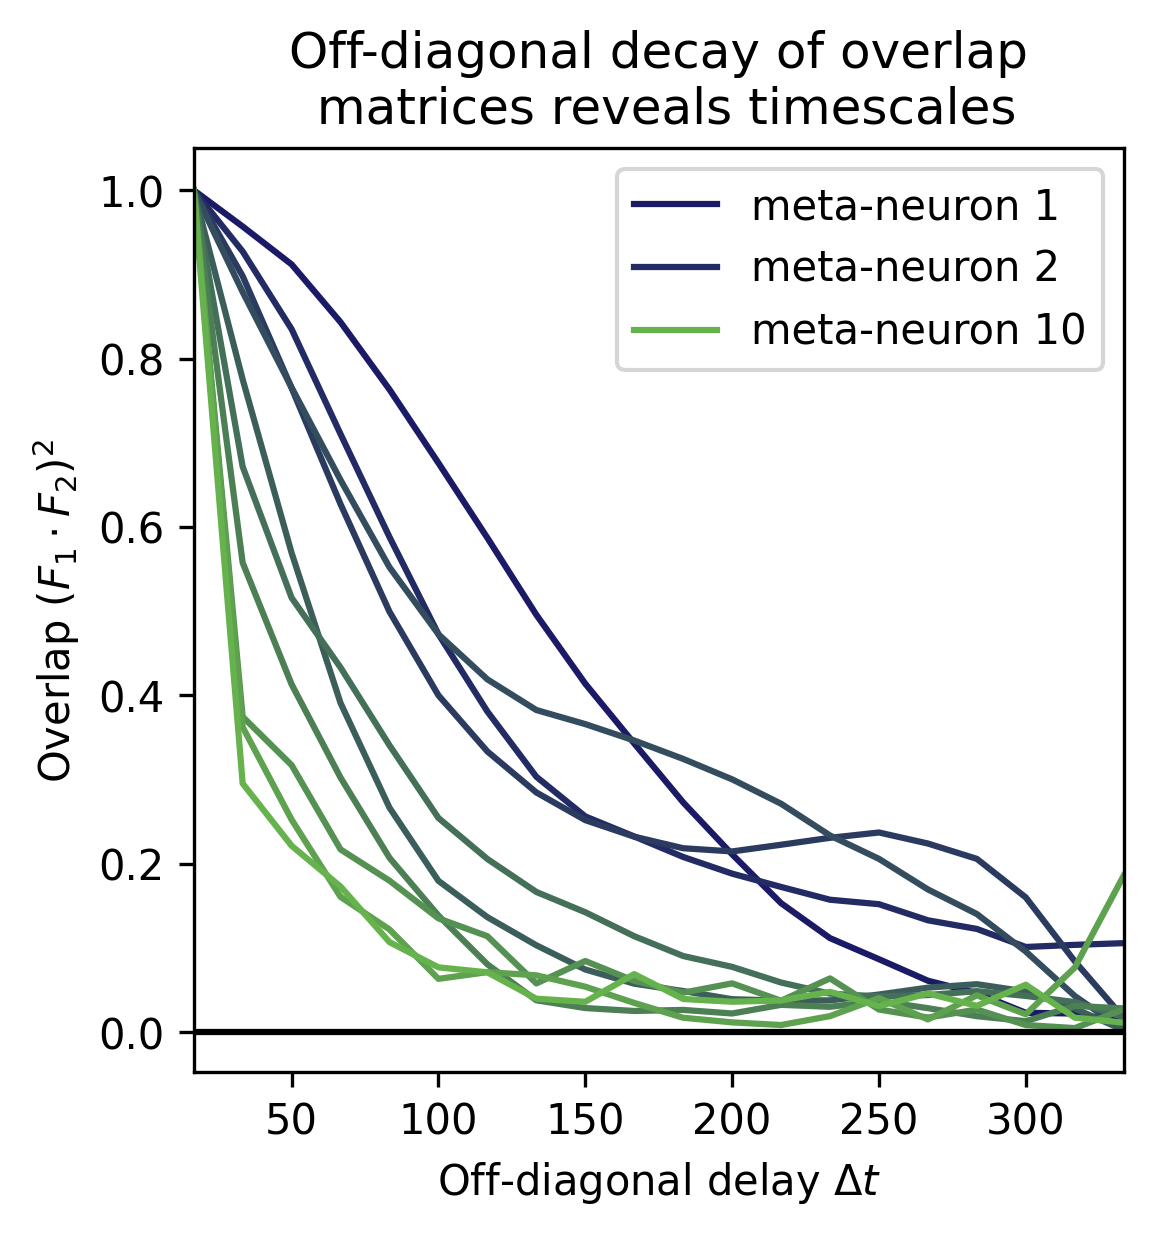

In [249]:
colors = linear_color(np.arange(N_modes), (0.1,0.1,0.4), (0.4,0.7,0.3))
x = (V_E_buffer_array + V_width) * 1000/60
label_range = {0,1,N_modes-1}

plt.figure(figsize=[4,4], dpi=300)
for i in range(N_modes):
    if i in label_range:
        plt.plot(x, off_diags_averaged[i], color=colors[i], label=f"meta-neuron {i+1}")
    else:
        plt.plot(x, off_diags_averaged[i], color=colors[i])

# plt.axhline(1/len(V_E_buffer_array)**2)
plt.axhline(0, color='k')
ax = plt.gca()
ax.set_title("Off-diagonal decay of overlap\n matrices reveals timescales")
ax.set_xlim(x[0],x[-1]);
ax.set_xlabel("Off-diagonal delay $\Delta t$")
ax.set_ylabel("Overlap $(F_1 \cdot F_2)^2$")
plt.legend()
# plt.x


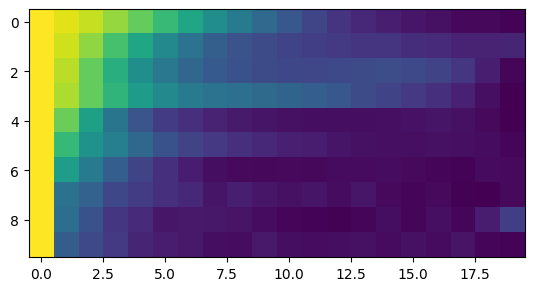

In [250]:
plt.imshow(off_diags_averaged)

## Mode viewing

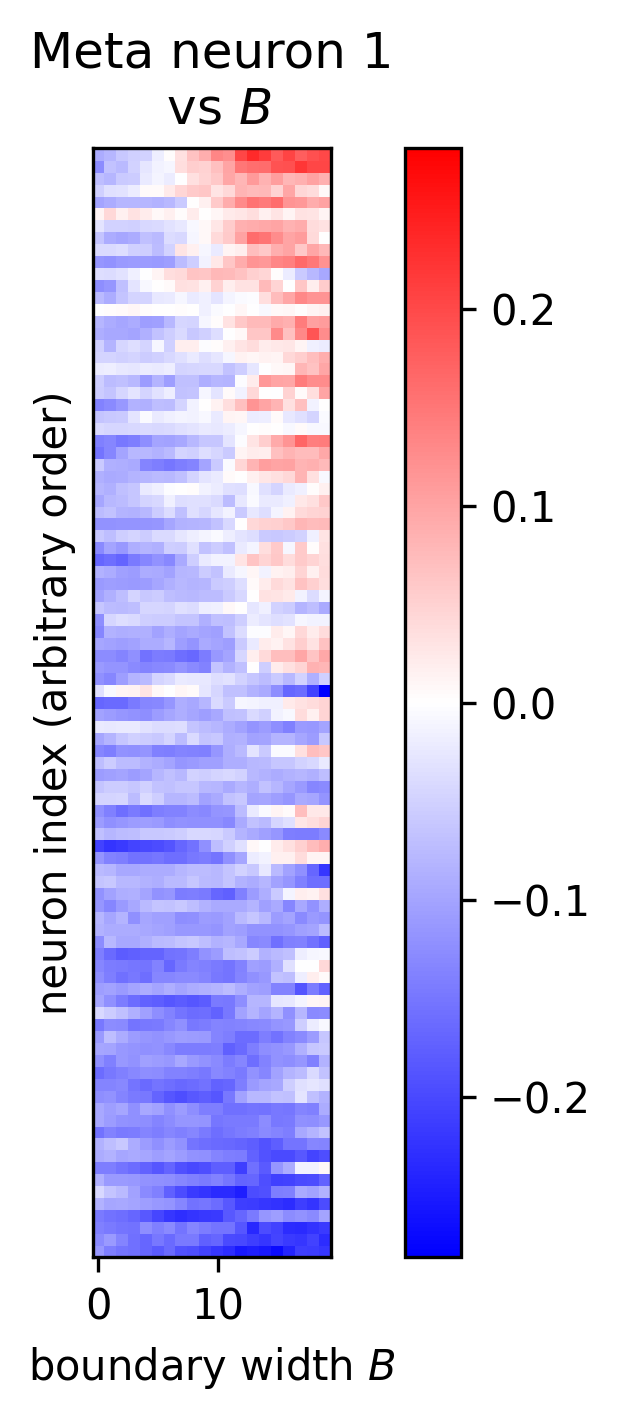

In [17]:
mode_index = 0
viewing_dims = (V_width, N)
modes = [a[:,mode_index].T.reshape(viewing_dims).T for a in basis_neurons]

plt.figure(dpi=300)
stacked = np.concatenate(modes, axis=1)
# sort_inds = np.argsort(np.sum(np.arange(V_width)[None,:]*stacked, axis=1))
sort_inds = np.argsort(np.sum(stacked, axis=1))
mx = np.amax(np.abs(stacked))
x = V_E_buffer_array
y = np.arange(N)
plt.pcolor(x, y, stacked[sort_inds], cmap='bwr', vmin=-mx, vmax=mx)
plt.title(f'Meta neuron {mode_index+1}\n vs $B$')
plt.xlabel('boundary width $B$')
plt.ylabel('neuron index (arbitrary order)')
ax = plt.gca()
ax.set_yticks([])
ax.set_aspect('equal')
plt.colorbar()

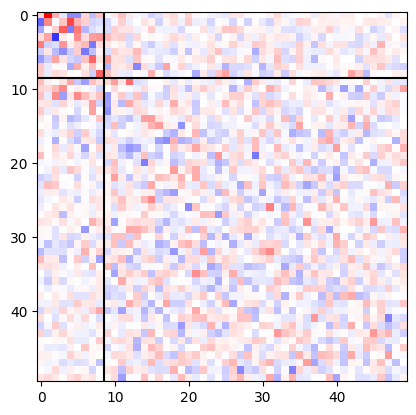

In [9]:
overlap = basis_neurons[0].T @ basis_neurons[-1]
# plt.imshow(np.abs(overlap[:5*K, :5*K]), cmap='Blues')
mx = np.max(np.abs(overlap))
plt.imshow(overlap[:5*K, :5*K], cmap='bwr', vmin=-mx, vmax=mx)
plt.axhline(K-1.5, color='k')
plt.axvline(K-1.5, color='k')

In [10]:
def collective_modes(modes, saturate=1.5, squared_entries=False, label_string="", plot_params={}):
        '''absolute_value option '''
        num_modes = len(modes)
        fig = plt.figure(constrained_layout=True, figsize=[num_modes,10], **plot_params)
        gs = mpl.gridspec.GridSpec(1, num_modes, figure=fig)
        ax = np.array([None]*(num_modes))
        for n in range(num_modes):
            ax[n] = fig.add_subplot(gs[0,n])
            cur_mode = modes[n]
            if squared_entries: 
                filter_plot = ax[n].imshow(cur_mode**2, interpolation='none', cmap='Blues')
            else:
                vmax = max(np.amax(cur_mode), -np.amin(cur_mode))
                filter_plot = ax[n].imshow(np.abs(cur_mode)**(1/saturate)*np.sign(cur_mode), cmap='bwr', vmax=vmax**(1/saturate), vmin=-vmax**(1/saturate))
            # ax[n].set_aspect('auto')
            ax[n].set_yticks([])
            ax[n].set_xticks([])
            ax[n].set_xlabel(label_string(n))
        return fig, ax

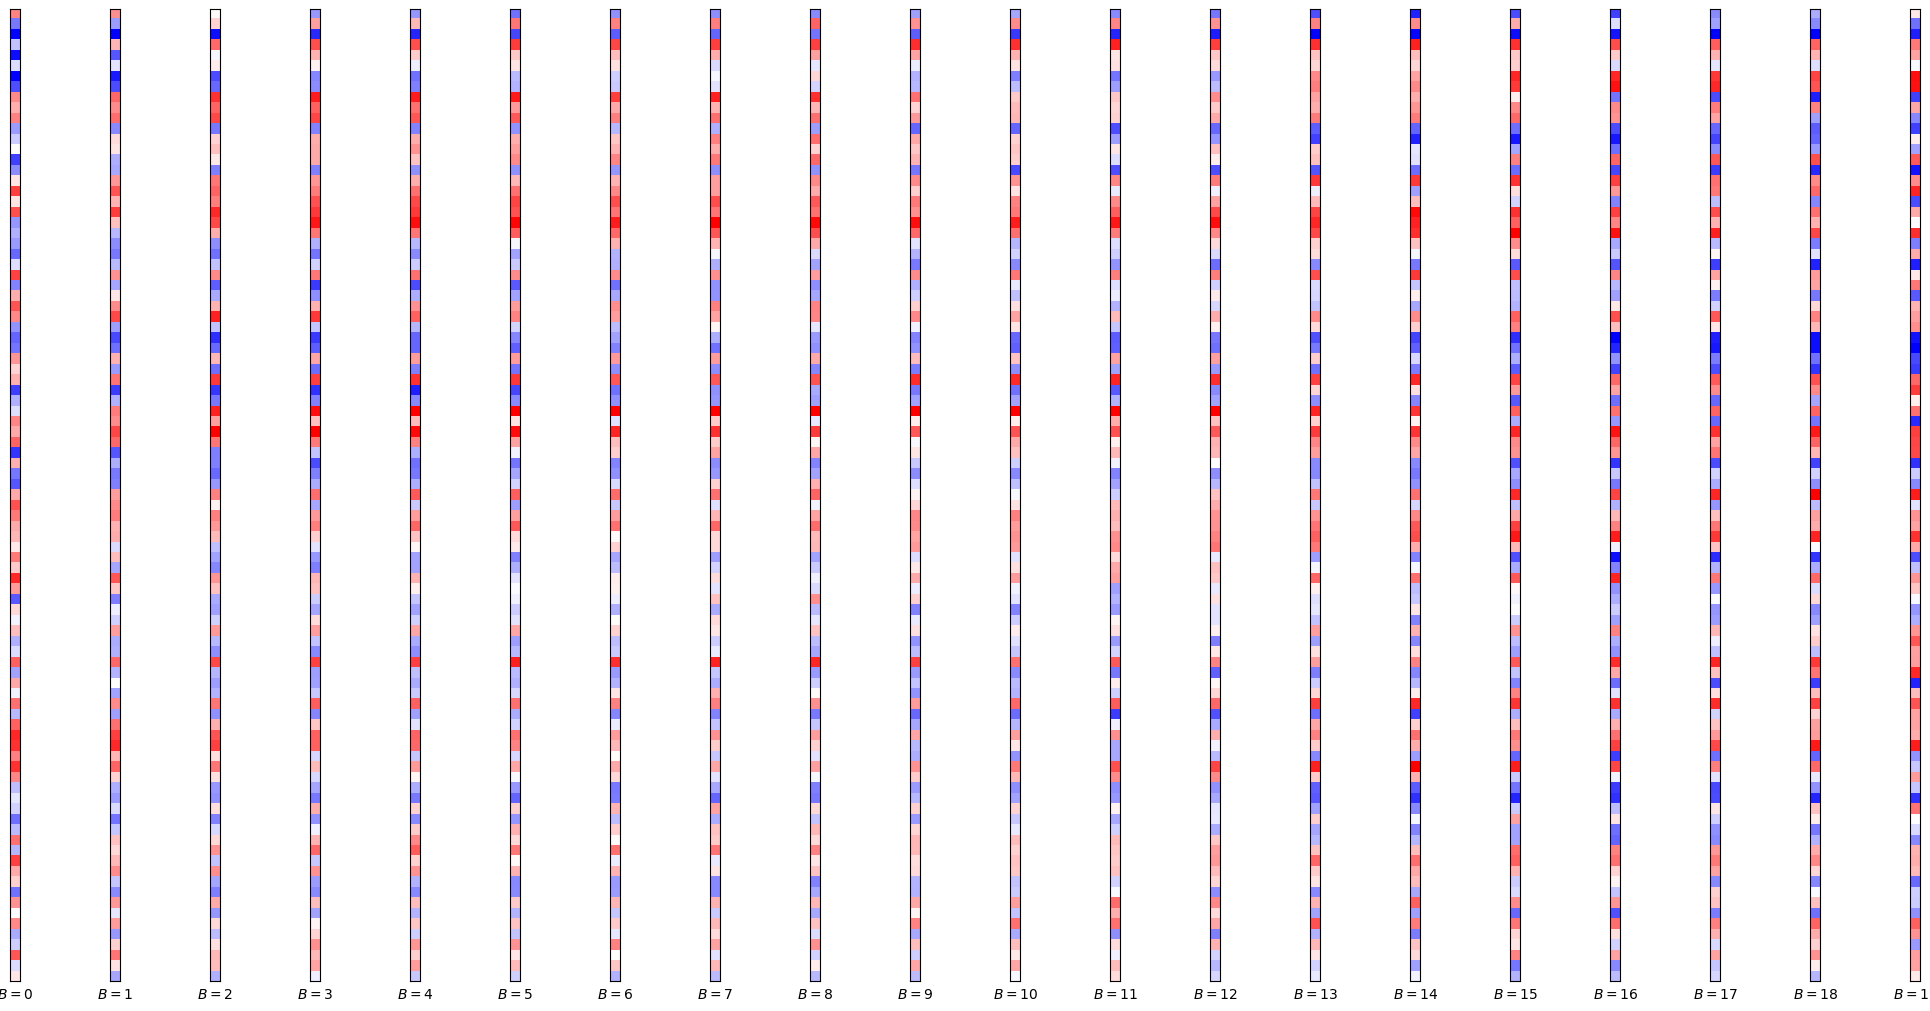

In [11]:
mode_index = 3
viewing_dims = (V_width, N)
modes = [a[:,mode_index].T.reshape(viewing_dims).T for a in basis_neurons]
collective_modes(modes, label_string=lambda n : f"$B = {n}$");

In [71]:
mode_1 = 0
mode_2 = 1

def get_stacked_modes(mode_index):
    modes = [a[:,mode_index].T.reshape(viewing_dims).T for a in basis_neurons]
    stacked = np.concatenate(modes, axis=1)
    return stacked
    
def get_sort_inds(mode_index):
    # f = 1-2*Flip
    stacked = get_stacked_modes(mode_index)
    # sort_inds = np.argsort(np.sum(np.arange(V_width)[None,:]*stacked, axis=1))
    return np.argsort(np.sum(stacked, axis=1))

In [72]:
sort_1 = get_sort_inds(mode_1)[::-1]
sort_2 = get_sort_inds(mode_2)[::-1]
stacked_sort = np.stack((sort_1,sort_2),axis=1)

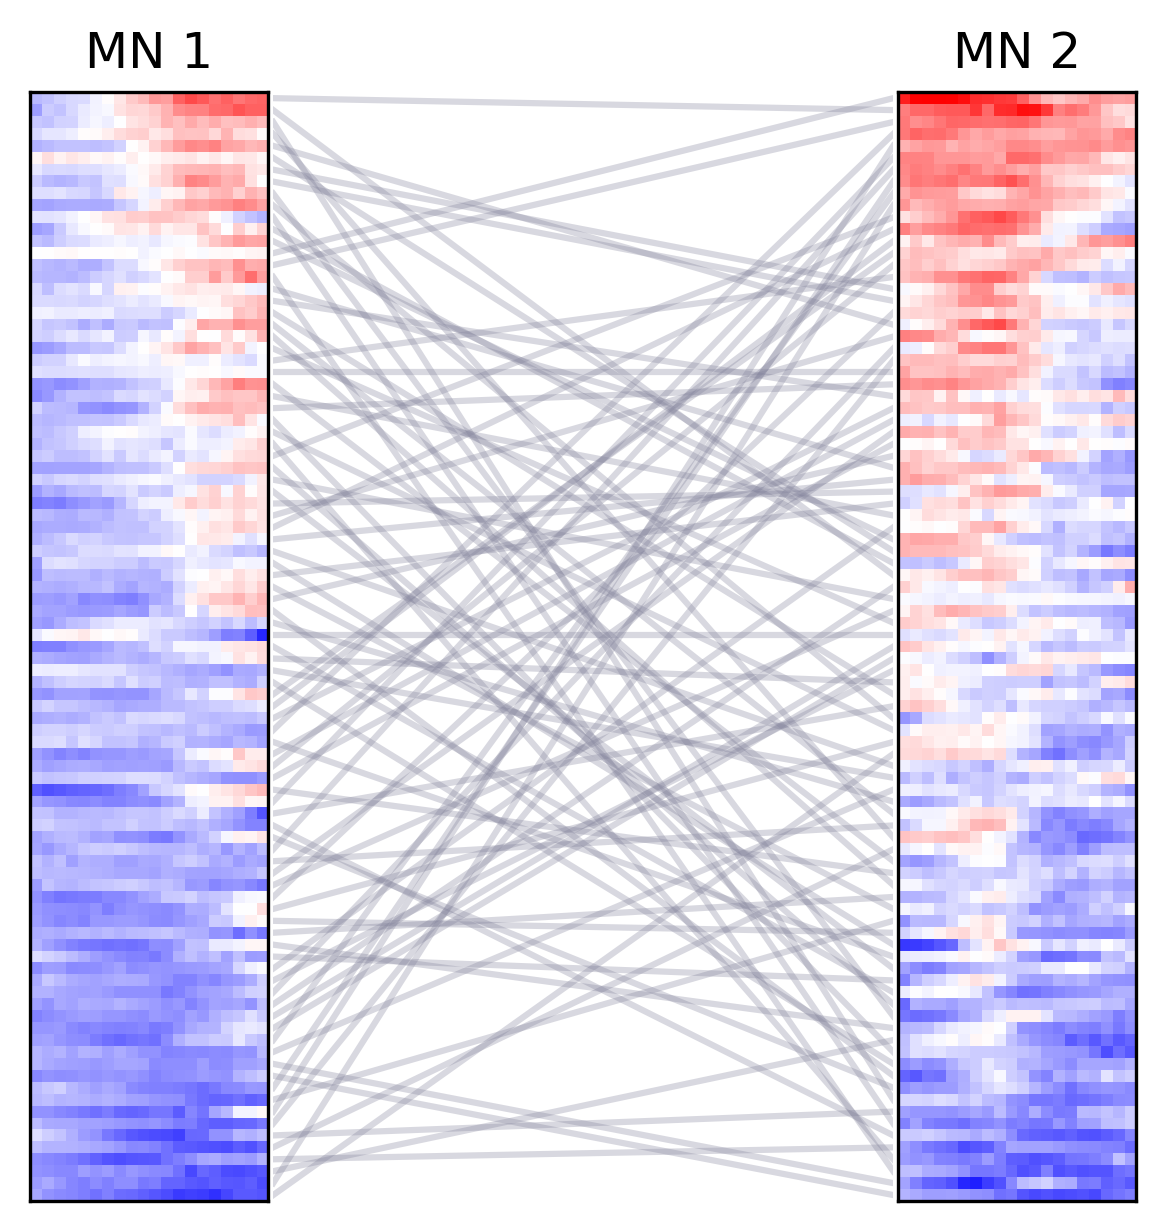

In [74]:
fig, ax = plt.subplots(ncols=3, dpi=300)

M1 = get_stacked_modes(mode_1) # reversing here makes left edge B=0
M2 = get_stacked_modes(mode_2)

mx =  max(np.amax(np.abs(M1)),np.amax(np.abs(M2)))

ax[0].imshow(M1[sort_1], cmap='bwr', vmin=-mx, vmax=mx)
ax[0].set_aspect('equal')
ax[0].set_xticks([])
ax[0].set_yticks([])
ax[0].set_title(f"MN {mode_1+1}")

ax[1].plot(stacked_sort.T, color=(0.5,0.5,0.6,0.3));
ax[1].axis('off')
ax[1].set_xlim(0,1)
ax[1].set_ylim(-0.5,len(sort_1)-0.5)

ax[2].imshow(M2[sort_2], cmap='bwr', vmin=-mx, vmax=mx)
ax[2].set_aspect('equal')
ax[2].set_xticks([])
ax[2].set_yticks([])
ax[2].set_title(f"MN {mode_2+1}")

plt.subplots_adjust(wspace=-0.3, hspace=0)